# 03 · Model Comparison
### IT3091 Machine Learning · Group 2026-AI-42 · Modelling & comparison lead

**Question.** Which family of model ranks clients best, and is the difference larger than the noise?
**Input:** the cleaned data and pipeline from notebook 02. **Output:** the model family selected for tuning (`artifacts/selection.json`).

Every candidate sits behind the **same preprocessing pipeline** and is scored on the **same folds**, so differences come from the model, not from the data handling.

| Model | Why included | Interpretability |
|---|---|---|
| **Dummy (prior)** | Baseline: what do we get with no information? | n/a |
| **Logistic regression** (balanced) | Strong, transparent benchmark; coefficients can be explained to compliance | High |
| **Random forest** (balanced) | Non-linear interactions, robust to scale and outliers | Medium |
| **Hist. gradient boosting** | Typically strongest on tabular data | Medium |
| **MLP (64-32)** | Does a neural model add anything on tabular data? | Low |
| Decision tree, gradient boosting, XGBoost, LightGBM, SVM | The remaining models named in the proposal (section 6 below) | varies |

**Two validation views.** Stratified 5-fold CV (shuffled; keeps class balance per fold) and **forward-chaining** CV (train on the past, validate on the next block). The data drift over time (EDA §9), so **forward-chaining is the better guide to a real campaign** and decides the selection.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))          # lets the notebook import the project code in src/
warnings.filterwarnings("ignore")

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

from src.config import *
from src.data.prepare import load_modelling_data
from src.data.loading import load_bank_full
from src.data.splits import deduplicate, split_xy
from src.evaluation.metrics import cv_eval, fc_eval, summarise, metric_row, scores_of
from src.features.preprocessing import build_pipeline, add_features, NUM_COLS, CAT_COLS, MACRO
from src.models.candidates import build_main_models, build_challenger_specs, hgb, MAIN_FAMILIES
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170)
FAST = False      # True = fewer folds, skips the slowest challenger, for a dry run
data = load_modelling_data()
X_train, y_train, X_test, y_test = data["X_train"], data["y_train"], data["X_test"], data["y_test"]
models = build_main_models()

Loading local file: bank-additional-full.csv
Rows: raw 41,188 -> cleaned 41,176 | train 32,940 (rate 6.38%) | pilot 500 | test 7,736 (rate 32.41%)


---
## 1 · Stratified cross-validation on the training period
Metrics are ranking- and budget-based because accuracy hides the minority class: **PR-AUC**, **ROC-AUC**, and precision / recall / **lift among the top `CALL_BUDGET` share of clients**. The dummy model's accuracy is shown once, to show why it is not used.

,roc_auc,pr_auc,precision_at_budget,recall_at_budget,lift_at_budget,accuracy_at_0_5,fit_seconds
Dummy (prior),0.5 +/- 0.0,0.064 +/- 0.0,0.065 +/- 0.003,0.205 +/- 0.01,1.026 +/- 0.048,0.936 +/- 0.0,0.179 +/- 0.01
Logistic regression,0.668 +/- 0.019,0.201 +/- 0.028,0.133 +/- 0.008,0.419 +/- 0.025,2.092 +/- 0.123,0.73 +/- 0.009,0.322 +/- 0.01
Random forest,0.66 +/- 0.01,0.197 +/- 0.023,0.139 +/- 0.008,0.435 +/- 0.026,2.173 +/- 0.128,0.909 +/- 0.002,2.147 +/- 0.318
Hist. gradient boosting,0.668 +/- 0.012,0.21 +/- 0.021,0.141 +/- 0.005,0.442 +/- 0.017,2.209 +/- 0.085,0.778 +/- 0.006,1.154 +/- 0.738
MLP (64-32),0.668 +/- 0.016,0.204 +/- 0.032,0.136 +/- 0.009,0.426 +/- 0.029,2.128 +/- 0.144,0.936 +/- 0.001,2.667 +/- 0.495


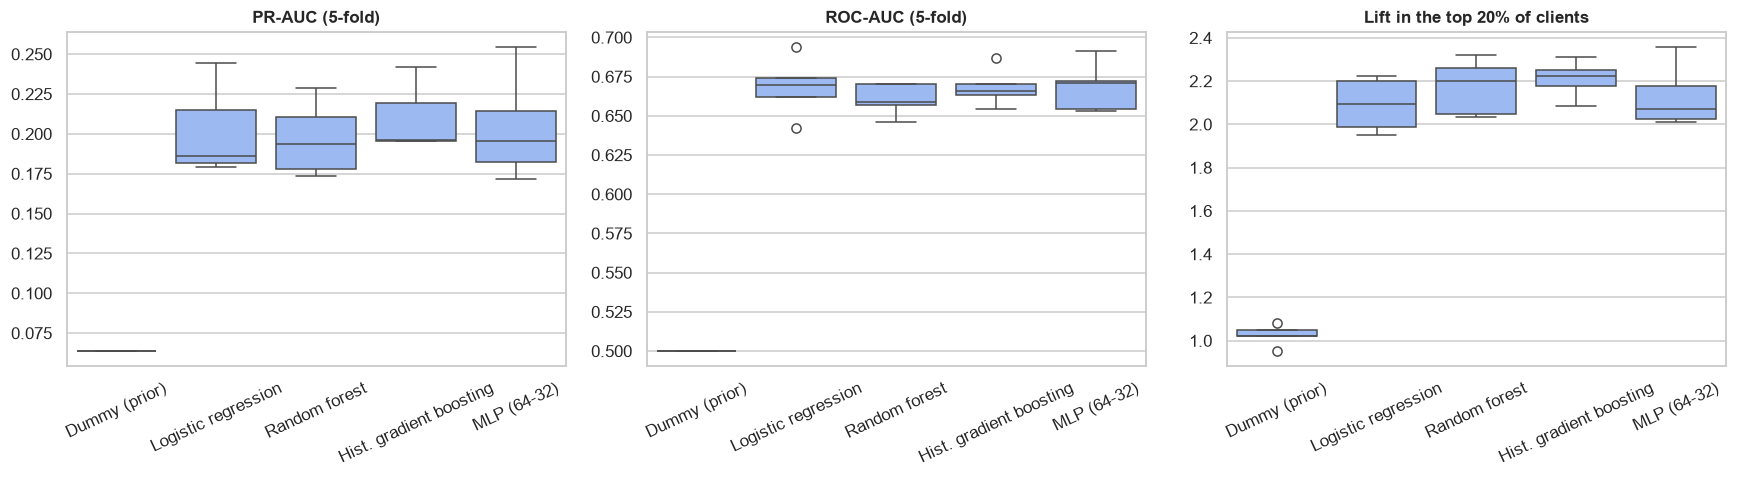

Dummy accuracy at 0.5 = 0.936 -> a good-looking number with zero business value.


In [2]:
cv_results = {name: cv_eval(p, X_train, y_train, 3 if FAST else 5) for name, p in models.items()}
cv_mean, cv_txt = summarise(cv_results)
display(cv_txt[["roc_auc", "pr_auc", "precision_at_budget", "recall_at_budget", "lift_at_budget", "accuracy_at_0_5", "fit_seconds"]])
cv_mean.to_csv(TABLES_DIR / "model_comparison_stratified_cv.csv")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, metric, title in zip(ax, ["pr_auc", "roc_auc", "lift_at_budget"], ["PR-AUC (5-fold)", "ROC-AUC (5-fold)", f"Lift in the top {CALL_BUDGET:.0%} of clients"]):
    sns.boxplot(data=pd.DataFrame({k: v[metric] for k, v in cv_results.items()}), ax=a, color="#8fb4ff"); a.set_title(title); a.tick_params(axis="x", rotation=25)
plt.tight_layout(); save_fig("model_cv_boxplots")
print("Dummy accuracy at 0.5 =", cv_mean.loc["Dummy (prior)", "accuracy_at_0_5"].round(3), "-> a good-looking number with zero business value.")

In [3]:
# Paired comparison: all models were scored on the SAME folds, so fold-wise differences are meaningful.
ref = "Hist. gradient boosting"
rows = []
for name, r in cv_results.items():
    if name in (ref, "Dummy (prior)"):
        continue
    d, da = cv_results[ref]["pr_auc"] - r["pr_auc"], cv_results[ref]["roc_auc"] - r["roc_auc"]
    rows.append({"vs model": name, "mean PR-AUC gain of HGB": d.mean(), "SD of gain": d.std(), "folds HGB better (PR-AUC)": f"{int((d > 0).sum())}/{len(d)}",
                 "mean ROC-AUC gain of HGB": da.mean(), "folds HGB better (ROC-AUC)": f"{int((da > 0).sum())}/{len(da)}"})
display(pd.DataFrame(rows).set_index("vs model").round(4))
print("Rule of thumb: with five folds, a gain below ~1-2x its SD, or one that does not appear in every fold, is NOT evidence of a real difference.")

,mean PR-AUC gain of HGB,SD of gain,folds HGB better (PR-AUC),mean ROC-AUC gain of HGB,folds HGB better (ROC-AUC)
vs model,,,,,
Logistic regression,0.0086,0.0076,4/5,-0.0004,2/5
Random forest,0.0129,0.0079,5/5,0.0077,3/5
MLP (64-32),0.0061,0.0138,4/5,-0.0002,2/5


Rule of thumb: with five folds, a gain below ~1-2x its SD, or one that does not appear in every fold, is NOT evidence of a real difference.


**Reading.** Compare models on PR-AUC and lift, and check the fold-to-fold spread. If two models overlap within noise, prefer the simpler, more interpretable one. Stratified folds mix early and late contacts, so they are a *first* look; the next section is the one that decides.

---
## 2 · Time-aware comparison (forward-chaining)
Every fold trains on the **past** and validates on the **next block**: the way a model would really be used. Random CV flatters models that exploit the *time period* rather than the *client*, so if the ranking here differs from section 1, the forward-chaining ranking is the better guide.

In [4]:
fc_models = {k: models[k] for k in ["Logistic regression", "Random forest", "Hist. gradient boosting", "MLP (64-32)"]}
fc_results = {name: fc_eval(p, X_train, y_train) for name, p in fc_models.items()}
fc_mean, fc_txt = summarise(fc_results)
display(fc_txt[["roc_auc", "pr_auc", "lift_at_budget"]])
fc_mean.to_csv(TABLES_DIR / "model_comparison_forward_chaining.csv")
print("Validation base rate per forward-chaining fold:", fc_results["Logistic regression"]["val_base_rate"].round(3).tolist())

,roc_auc,pr_auc,lift_at_budget
Logistic regression,0.539 +/- 0.081,0.098 +/- 0.083,1.229 +/- 0.491
Random forest,0.526 +/- 0.071,0.087 +/- 0.064,1.214 +/- 0.326
Hist. gradient boosting,0.53 +/- 0.07,0.088 +/- 0.065,1.218 +/- 0.273
MLP (64-32),0.52 +/- 0.021,0.081 +/- 0.048,1.189 +/- 0.203


Validation base rate per forward-chaining fold: [0.044, 0.063, 0.055, 0.127]


**Reading.** Absolute scores are lower and more variable here than in section 1, and the validation blocks have different base rates. That gap *is* the honest estimate of deployment risk: a model trained on yesterday's market is scored on tomorrow's. PR-AUC also depends on the base rate, so across folds compare **lift** and **ROC-AUC** as well.

---
## 3 · The remaining models named in the proposal
The proposal also lists a Decision Tree, Gradient Boosting, an optional SVM (§11) and XGBoost / LightGBM (§15). They enter as **challengers** with the same pipeline, folds and metrics. An exact RBF-kernel SVM scales quadratically with rows, so the SVM is approximated by **Nystroem features + a linear SVM** (it outputs a decision value, so only its *ranking* is compared). Fit time is reported because the proposal also judges operational feasibility.

**Rule for a challenger to displace the incumbent (fixed before running):** higher mean forward-chaining PR-AUC **and** better in at least 3 of 4 folds. Otherwise the simpler or already-chosen model stays.

,group,cv_pr_auc,cv_pr_auc_sd,fc_pr_auc,fc_pr_auc_sd,fc_roc_auc,fc_lift,fit_seconds
model,,,,,,,,
Logistic regression,main,0.201,0.028,0.098,0.083,0.539,1.229,0.322
Hist. gradient boosting,main,0.210,0.021,0.088,0.065,0.530,1.218,1.154
SVM (RBF approx.),challenger,0.192,0.026,0.088,0.068,0.526,1.138,5.876
Random forest,main,0.197,0.023,0.087,0.064,0.526,1.214,2.147
XGBoost,challenger,0.205,0.023,0.083,0.057,0.520,1.095,4.272
MLP (64-32),main,0.204,0.032,0.081,0.048,0.520,1.189,2.667
LightGBM,challenger,0.201,0.028,0.079,0.050,0.512,1.045,13.161
Decision tree,challenger,0.173,0.018,0.078,0.052,0.501,1.030,0.418
Gradient boosting (sklearn),challenger,0.202,0.019,0.075,0.041,0.511,1.008,13.076


,incumbent,mean_pr_auc_gain,sd_of_gain,folds_better,verdict
challenger,,,,,
Decision tree,Logistic regression,-0.0194,0.0318,0/4,keep incumbent
Gradient boosting (sklearn),Logistic regression,-0.0229,0.0427,1/4,keep incumbent
XGBoost,Logistic regression,-0.0144,0.0271,1/4,keep incumbent
LightGBM,Logistic regression,-0.0184,0.0343,1/4,keep incumbent
SVM (RBF approx.),Logistic regression,-0.0100,0.0155,0/4,keep incumbent


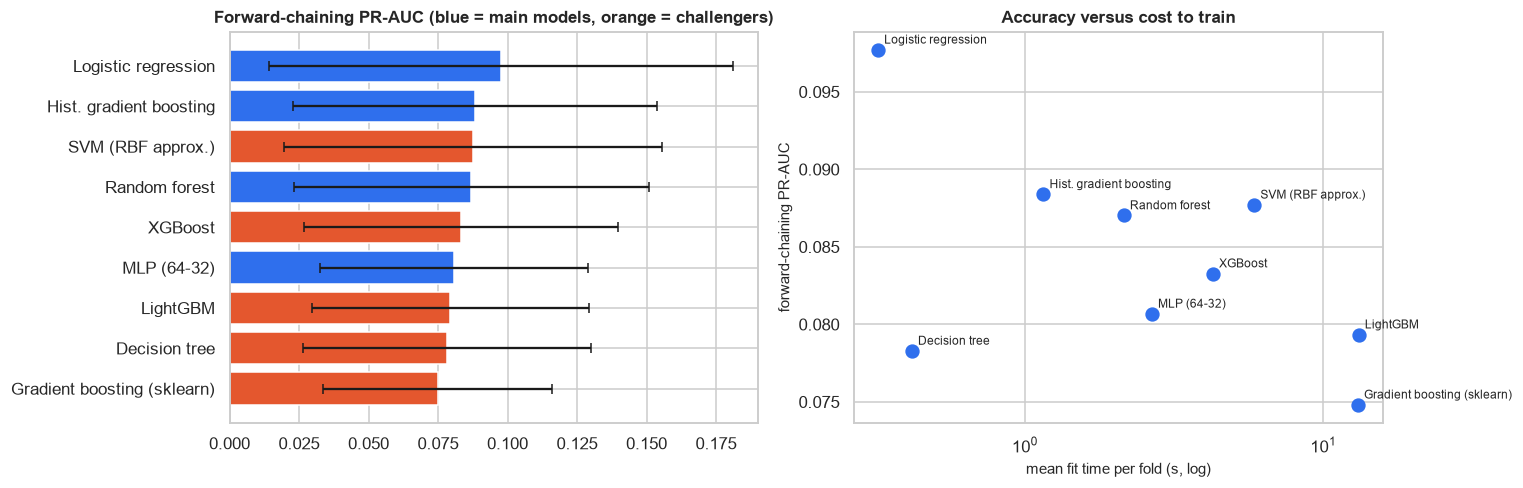

In [5]:
zoo_specs = build_challenger_specs(y_train)
if FAST:
    zoo_specs.pop("Gradient boosting (sklearn)")
zoo_cv = {k: cv_eval(build_pipeline(m, scale=sc), X_train, y_train, 3 if FAST else 5) for k, (m, sc) in zoo_specs.items()}
zoo_fc = {k: fc_eval(build_pipeline(m, scale=sc), X_train, y_train) for k, (m, sc) in zoo_specs.items()}

rows = []
for src_, names, cvd, fcd in [("main", list(fc_results), cv_results, fc_results), ("challenger", list(zoo_specs), zoo_cv, zoo_fc)]:
    for k in names:
        rows.append(dict(model=k, group=src_, cv_pr_auc=cvd[k]["pr_auc"].mean(), cv_pr_auc_sd=cvd[k]["pr_auc"].std(),
                         fc_pr_auc=fcd[k]["pr_auc"].mean(), fc_pr_auc_sd=fcd[k]["pr_auc"].std(), fc_roc_auc=fcd[k]["roc_auc"].mean(),
                         fc_lift=fcd[k]["lift_at_budget"].mean(), fit_seconds=cvd[k]["fit_seconds"].mean()))
zoo_table = pd.DataFrame(rows).set_index("model").sort_values("fc_pr_auc", ascending=False)
display(zoo_table.round(3))
zoo_table.to_csv(TABLES_DIR / "model_comparison_all_models.csv")

ref_main = max(MAIN_FAMILIES, key=lambda k: fc_results[k]["pr_auc"].mean())
rows = []
for k in zoo_specs:
    d = zoo_fc[k]["pr_auc"] - fc_results[ref_main]["pr_auc"]
    rows.append(dict(challenger=k, incumbent=ref_main, mean_pr_auc_gain=d.mean(), sd_of_gain=d.std(), folds_better=f"{int((d > 0).sum())}/{len(d)}",
                     verdict="consider switching" if (d.mean() > 0 and (d > 0).sum() >= 3) else "keep incumbent"))
display(pd.DataFrame(rows).set_index("challenger").round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
t = zoo_table.sort_values("fc_pr_auc")
ax[0].barh(t.index, t["fc_pr_auc"], xerr=t["fc_pr_auc_sd"], color=[C_MAIN if g == "main" else C_WARN for g in t["group"]], capsize=3)
ax[0].set_title("Forward-chaining PR-AUC (blue = main models, orange = challengers)")
ax[1].scatter(zoo_table["fit_seconds"], zoo_table["fc_pr_auc"], s=70, color=C_MAIN)
for k, r in zoo_table.iterrows():
    ax[1].annotate(k, (r["fit_seconds"], r["fc_pr_auc"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[1].set_xscale("log"); ax[1].set_xlabel("mean fit time per fold (s, log)"); ax[1].set_ylabel("forward-chaining PR-AUC"); ax[1].set_title("Accuracy versus cost to train")
plt.tight_layout(); save_fig("model_zoo")

---
## 4 · Selecting the family to tune
The family is chosen by **forward-chaining PR-AUC among the three main families** (logistic regression, random forest, histogram gradient boosting), the same rule that notebook 04 reads. Challengers are reported, not silently promoted: they displace the incumbent only under the rule in section 3.

In [6]:
best_family = max(MAIN_FAMILIES, key=lambda k: fc_results[k]["pr_auc"].mean())
print("Family chosen by forward-chaining PR-AUC:", best_family, f"({fc_results[best_family]['pr_auc'].mean():.3f})")
print("Highest stratified-CV PR-AUC            :", cv_mean["pr_auc"].idxmax(), f"({cv_mean['pr_auc'].max():.3f})")
(ARTIFACTS_DIR / "selection.json").write_text(json.dumps({"best_family": best_family}, indent=2))

Family chosen by forward-chaining PR-AUC: Logistic regression (0.098)
Highest stratified-CV PR-AUC            : Hist. gradient boosting (0.210)


42

---
## 5 · Which data version, and do the macro indicators help out of time?

Two data decisions were deliberately left open by the proposal and the EDA, and are settled with a measurement here. Three variants, the same model settings, the same chronological design:

* **A** `bank-full.csv`: the proposal's choice (16 attributes; it has `balance` and `day`, which the other file lacks)
* **B** `bank-additional-full.csv`: client and campaign attributes only (no macro indicators): **this project's default**
* **C** `bank-additional-full.csv` plus the five macro indicators

*A vs B* asks "does the file version matter?"; *B vs C* asks "do the macro indicators add anything that survives the time split?". Base rates differ between files, so compare **lift** and ROC-AUC rather than raw PR-AUC. **Rule fixed in advance:** keep B unless A beats B and C on **both** forward-chaining and hold-out lift. This is a *data* comparison, not model selection: the hold-out values here are for the version decision only and do not touch the final model.

Loading local file: bank-full.csv


train_rate  fc_pr_auc  fc_roc_auc  fc_lift  fc_lift_sd  hold_roc_auc  hold_pr_auc  hold_lift
version                 model                                                                                                                
A  bank-full (proposal) Logistic regression           0.067      0.093       0.555    1.260       0.152         0.678        0.496      1.748
                        Hist. gradient boosting       0.067      0.094       0.546    1.243       0.139         0.679        0.484      1.644
B  additional, no macro Logistic regression           0.064      0.098       0.539    1.229       0.491         0.691        0.502      1.725
                        Hist. gradient boosting       0.064      0.088       0.530    1.198       0.245         0.660        0.466      1.648
C  additional + 5 macro Logistic regression           0.064      0.076       0.516    0.920       0.291         0.695        0.511      1.783
                        Hist. gradient boosting       0.064      0.079       0.517    1.145       0.140         0.608        0.416      1.540

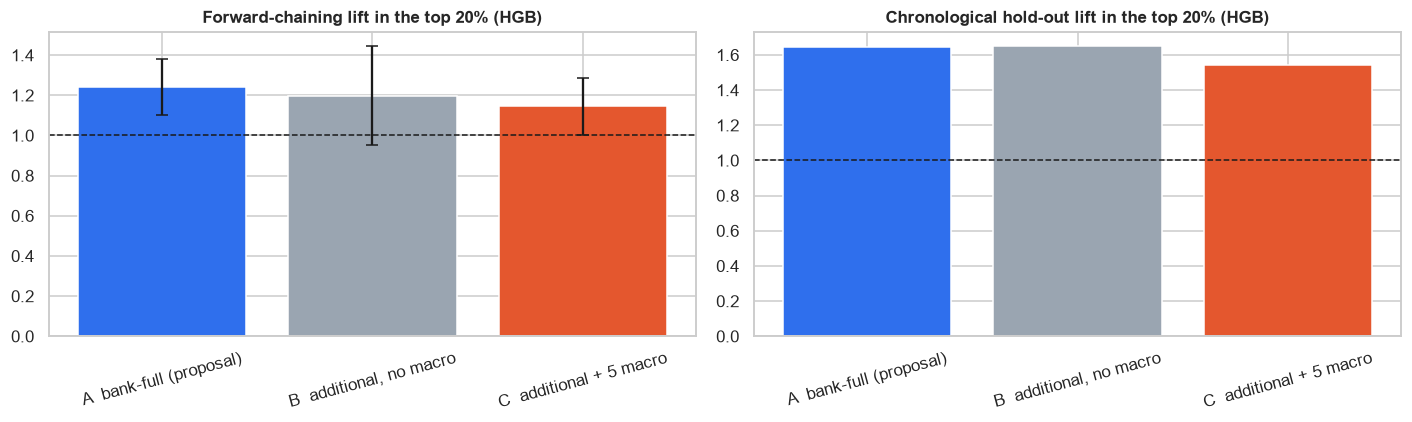

In [7]:
try:
    bf_raw = load_bank_full()
    HAVE_BF = True
except Exception as e:
    print("bank-full.csv is not available (", type(e).__name__, "); variants B and C are still compared.")
    HAVE_BF = False

def bf_features(X):
    X = X.copy()
    X["was_contacted_before"] = (X["pdays"] != -1).astype(int)
    X["pdays"] = X["pdays"].where(X["pdays"] != -1, 0)
    X["campaign_log"] = np.log1p(X["campaign"])
    X["balance_slog"] = np.sign(X["balance"]) * np.log1p(np.abs(X["balance"]))     # heavy-tailed, can be negative
    X["education_ord"] = X["education"].map({"primary": 1, "secondary": 2, "tertiary": 3})
    return X
BF_NUM = ["age", "balance_slog", "day", "campaign", "campaign_log", "pdays", "previous", "was_contacted_before", "education_ord"]
BF_CAT = ["job", "marital", "default", "housing", "loan", "contact", "month", "poutcome"]

def chrono(X_, y_):
    c = int(len(X_) * (1 - TEST_FRACTION))                       # same design as notebook 02, including the pilot gap
    return X_.iloc[:c].reset_index(drop=True), y_[:c], X_.iloc[c + PILOT_ROWS:].reset_index(drop=True), y_[c + PILOT_ROWS:]

no_macro = [c for c in NUM_COLS if c not in MACRO]
versions = {"B  additional, no macro": dict(fe=add_features, num=no_macro, cat=CAT_COLS, d=(X_train, y_train, X_test, y_test)),
            "C  additional + 5 macro": dict(fe=add_features, num=NUM_COLS, cat=CAT_COLS, d=(X_train, y_train, X_test, y_test))}
if HAVE_BF:
    bf = deduplicate(bf_raw); bf_X, bf_y = split_xy(bf)
    versions = {"A  bank-full (proposal)": dict(fe=bf_features, num=BF_NUM, cat=BF_CAT, d=chrono(bf_X, bf_y)), **versions}

VER_MODELS = {"Logistic regression": (lambda: LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), True),
              "Hist. gradient boosting": (lambda: hgb(learning_rate=0.06, max_iter=200, class_weight="balanced"), False)}
rows = []
for vname, v in versions.items():
    Xtr, ytr, Xte, yte = v["d"]
    for mname, (factory, scale) in VER_MODELS.items():
        p = build_pipeline(factory(), scale=scale, fe=v["fe"], num=v["num"], cat=v["cat"])
        f = fc_eval(p, Xtr, ytr)
        h = metric_row(yte, scores_of(clone(p).fit(Xtr, ytr), Xte))
        rows.append(dict(version=vname, model=mname, train_rate=ytr.mean(), fc_pr_auc=f["pr_auc"].mean(), fc_roc_auc=f["roc_auc"].mean(),
                         fc_lift=f["lift_at_budget"].mean(), fc_lift_sd=f["lift_at_budget"].std(),
                         hold_roc_auc=h["roc_auc"], hold_pr_auc=h["pr_auc"], hold_lift=h["lift_at_budget"]))
ver_table = pd.DataFrame(rows).set_index(["version", "model"])
display(ver_table.round(3))
ver_table.to_csv(TABLES_DIR / "model_comparison_dataset_version.csv")

hg = ver_table.xs("Hist. gradient boosting", level="model")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cols = [C_MAIN, C_GREY, C_WARN][-len(hg):]
ax[0].bar(hg.index, hg["fc_lift"], yerr=hg["fc_lift_sd"], color=cols, capsize=4); ax[0].set_title(f"Forward-chaining lift in the top {CALL_BUDGET:.0%} (HGB)")
ax[1].bar(hg.index, hg["hold_lift"], color=cols); ax[1].set_title(f"Chronological hold-out lift in the top {CALL_BUDGET:.0%} (HGB)")
for a in ax:
    a.axhline(1, color="k", ls="--", lw=1); a.tick_params(axis="x", rotation=15)
plt.tight_layout(); save_fig("model_dataset_version")

**How to read it.** The macro question is *B vs C* on the **forward-chaining** columns: if C is not clearly better than B there (and not better on the hold-out for the same reason), the indicators are acting as a time proxy rather than adding stable client information, which supports `EXCLUDE_MACRO = True`. The data-version question is *A vs B*: if A is clearly better on both views, the proposal's original dataset choice was the stronger one and the group should say so. Either outcome is a legitimate, evidence-based reading; record it as decision D11 in `docs/decision_log.md`.